# 3. Amplitude, variance and growth

This notebook follows Secs. 2.4 and 2.5 of Paper I.
It builds the top-hat variance $\sigma(R)$, the amplitudes $\sigma_8$ and $S_8$, the growth factor and the growth rate, and the scale dependence massive neutrinos give the growth.
It ends on the figure of the amplitude gradients.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

from ggah_mod.cosmology import (PLANCK18, growth_factor, growth_scale_spread,
                                ln10A_s_for_sigma8, make_pk, s8, sigma2_tophat,
                                sigma8, tophat_window)
from ggah_mod.cosmology.growth import f_sigma8, growth_rate

pk = make_pk("emu_pk")
c = PLANCK18

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = False


## The top-hat window

The variance of the linear field smoothed on a scale $R$ uses the Fourier transform of a real-space top hat, evaluated in two branches (Eq. 25):

$$W(x) = \begin{cases} 1 - x^2/10 + x^4/280, & x < 0.1,\\ 3(\sin x - x\cos x)/x^3, & x \ge 0.1.\end{cases}$$

The series is a requirement: the closed form cancels catastrophically at small $x$.
Both branches are evaluated and selected with `where`, the unused one held finite, so the gradient is clean at the switch.

dW/dx either side of the switch: [-0.01998569 -0.01998572 -0.01998574]


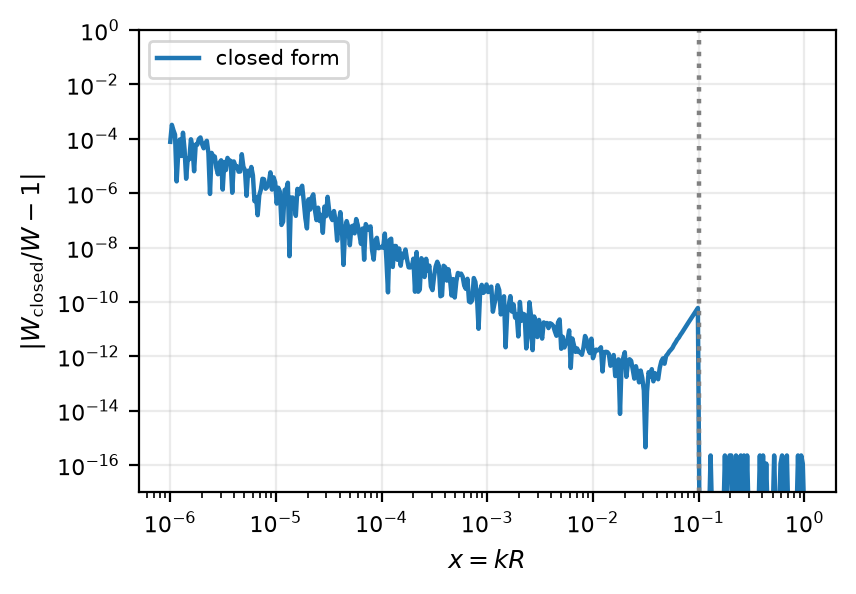

In [2]:
x = np.logspace(-6, 0, 400)
closed = 3 * (np.sin(x) - x * np.cos(x)) / x**3
fig, ax = plt.subplots(figsize=(4.5, 3.0))
ax.loglog(x, np.abs(closed / tophat_window(x) - 1) + 1e-18, label="closed form")
ax.axvline(0.1, color="0.5", ls=":")
ax.set(xlabel="$x = kR$", ylabel=r"$|W_{\rm closed}/W - 1|$", ylim=(1e-17, 1))
ax.legend()

dW = jax.vmap(jax.grad(tophat_window))(jnp.array([0.0999999, 0.1, 0.1000001]))
print("dW/dx either side of the switch:", np.asarray(dW))

The closed form loses about twelve significant digits at $x\sim10^{-4}$; the series is accurate to machine precision below the switch.

## The variance and the amplitudes

The variance is a trapezoid in $\ln k$ (Eq. 26),

$$\sigma^2(R) = \frac{1}{2\pi^2}\int P(k)\,W^2(kR)\,k^3\,{\rm d}\ln k,$$

and the amplitudes follow, $\sigma_8 = \sigma(8\,h^{-1}{\rm Mpc})$ on $P_{\rm m}$ and $S_8 = \sigma_8\sqrt{\Omega_{\rm m}/0.3}$ (Eq. 27).
Both take the total-matter spectrum, as the priors quoted on them assume.

In [3]:
k = np.logspace(-4, 2, 512)
P0 = pk.pk(k, 0.0, c)
print(f"sigma8 = {float(sigma8(P0, k)):.5f},  S8 = {float(s8(P0, k, c)):.5f}")
print(f"sigma(8 Mpc/h) on P_cb = {float(sigma8(pk.pk_cb(k, 0.0, c), k)):.5f}")

# the trapezoid on 512 wavenumbers against a 4096-point grid
kf = np.logspace(-4, 2, 4096)
Pf = pk.pk(kf, 0.0, c)
for R in (1.0, 8.0, 30.0):
    r = np.sqrt(sigma2_tophat(P0, k, R) / sigma2_tophat(Pf, kf, R)) - 1
    print(f"R = {R:4g} Mpc/h: sigma(512) / sigma(4096) - 1 = {float(r):+.1e}")

sigma8 = 0.81325,  S8 = 0.83373
sigma(8 Mpc/h) on P_cb = 0.81687


R =    1 Mpc/h: sigma(512) / sigma(4096) - 1 = +9.5e-09
R =    8 Mpc/h: sigma(512) / sigma(4096) - 1 = -3.1e-08
R =   30 Mpc/h: sigma(512) / sigma(4096) - 1 = -9.7e-08


$\sigma_8$ is an output.
To start from a requested $\sigma_8$, solve once for the amplitude and carry it.

In [4]:
lnA = ln10A_s_for_sigma8(0.78, c, pk, k=k)
print(f"ln10A_s = {lnA:.5f} gives sigma8 = {float(sigma8(pk.pk(k, 0.0, c.replace(ln10A_s=lnA)), k)):.6f}")

ln10A_s = 2.96051 gives sigma8 = 0.780000


## Growth

There is one growth factor in this package, the ratio of the top-hat amplitudes of the spectrum at two redshifts (Eq. 28),

$$D_X(z) = \frac{\sigma_8[P_X(k,z)]}{\sigma_8[P_X(k,0)]},\qquad X \in \{{\rm m}, {\rm cb}\}.$$

No fitting formula and no separate ODE.
The growth rate $f = {\rm d}\ln D/{\rm d}\ln a$ is a second-order difference in $\ln(1+z)$ with a step of $10^{-3}$ (Eq. 29).

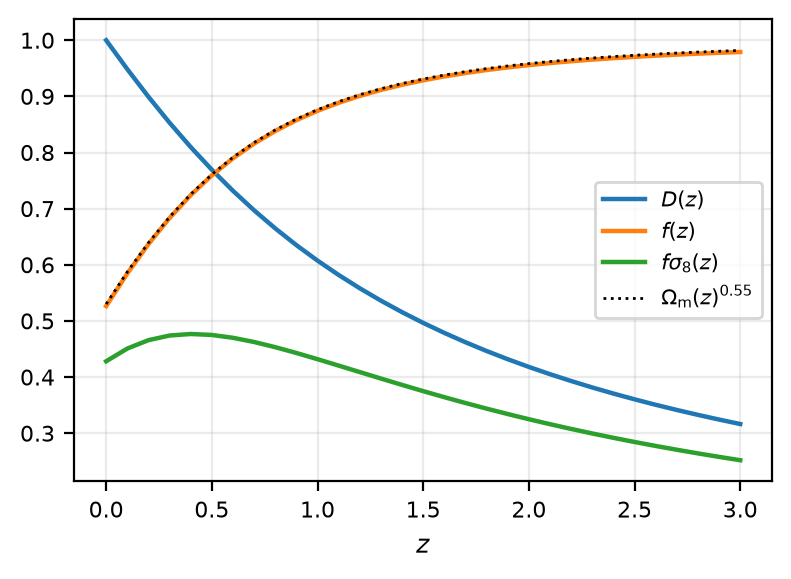

In [5]:
z = np.linspace(0.0, 3.0, 31)
D, f, fs8 = growth_factor(z, c, pk, k=k), growth_rate(z, c, pk, k=k), f_sigma8(z, c, pk, k=k)
fig, ax = plt.subplots(figsize=(4.5, 3.0))
ax.plot(z, D, label="$D(z)$")
ax.plot(z, f, label="$f(z)$")
ax.plot(z, fs8, label=r"$f\sigma_8(z)$")
omz = c.Omega_m * (1 + z) ** 3 / (c.Omega_m * (1 + z) ** 3 + c.Omega_de)
ax.plot(z, omz ** 0.55, "k:", lw=1, label=r"$\Omega_{\rm m}(z)^{0.55}$")
ax.set(xlabel="$z$")
ax.legend();

The dotted line is the familiar approximation $f \simeq \Omega_{\rm m}(z)^{0.55}$, for comparison.

## Scale-dependent growth

With massive neutrinos, free streaming suppresses small scales more than large ones, so $\sqrt{P(k,z)/P(k,0)}$ depends on $k$ and a scalar $D(z)$ is ambiguous.
`growth_scale_spread` measures the ambiguity (Eq. 30),
$\mathcal{S}(z) = \max_k |\sqrt{P(k,z)/P(k,0)}/D(z) - 1|$ over $10^{-3} < k < 10$.
The paper, with CLASS, finds $5.6\times10^{-5}$ at $z = 0.5$ with massless neutrinos, $6.8\times10^{-4}$ at 0.06 eV and $3.0\times10^{-3}$ at 0.30 eV.
The emulator's own error sets a floor of a few $10^{-4}$ here.

In [6]:
for sum_mnu in (0.0, 0.06, 0.3):
    cc = c.replace(sum_mnu=sum_mnu)
    print(f"sum m_nu = {sum_mnu:4.2f} eV: S(z=0.5) = {float(growth_scale_spread(0.5, cc, pk)):.1e}")

sum m_nu = 0.00 eV: S(z=0.5) = 1.4e-04
sum m_nu = 0.06 eV: S(z=0.5) = 7.7e-04
sum m_nu = 0.30 eV: S(z=0.5) = 2.9e-03


## Derivatives and the figure

Fig. 4 of the paper differentiates $\ln\sigma_8(z)$ and $\ln D(z)$ with respect to the ten parameters, both off one total-matter spectrum on one $k$ grid.
Nothing on $\sigma_8$ is exactly zero, unlike the background of notebook 01: $\sigma_8$ integrates the spectrum, so every parameter that moves $P(k)$ moves it.
Two exact statements check the figure: $\partial\ln\sigma_8/\partial\ln(10^{10}A_{\rm s}) = 1/2$ at every redshift, since $\sigma_8 \propto \sqrt{A_{\rm s}}$, and the amplitude cancels from $D$, a ratio of two $\sigma_8$ at one amplitude.

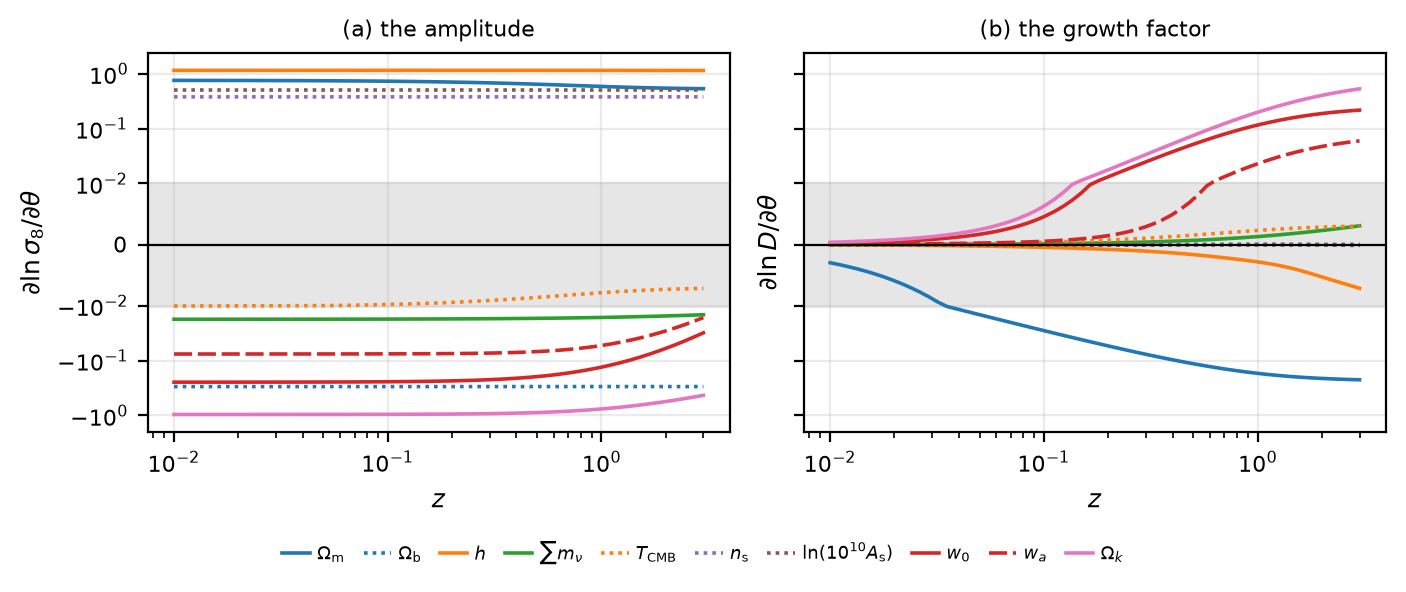

In [7]:
z = np.geomspace(0.01, 3.0, 20 if FAST else 60)
zj, kj = jnp.asarray(z), jnp.asarray(k)
gs, gd = {}, {}
for p in T.DPARAMS:
    v0 = float(getattr(c, p))
    scale = v0 if p in T.DLOG else 1.0

    def lns8(v, p=p):
        cc = c.replace(**{p: v})
        return jnp.log(jnp.array([sigma8(pk.pk(kj, zz, cc), kj) for zz in z]))

    def lnD(v, p=p):
        return jnp.log(growth_factor(zj, c.replace(**{p: v}), pk, k=k))

    gs[p] = np.asarray(jax.jacfwd(lns8)(v0)) * scale
    gd[p] = np.asarray(jax.jacfwd(lnD)(v0)) * scale

LIN = 1e-2
fig, ax = plt.subplots(1, 2, figsize=(7.1, 2.9), sharey=True)
for axis, g, name, title in ((ax[0], gs, r"\sigma_8", "(a) the amplitude"),
                             (ax[1], gd, "D", "(b) the growth factor")):
    axis.axhspan(-LIN, LIN, color="0.90", zorder=0)
    for p in T.DPARAMS:
        colour, ls = T.DSTYLE[p]
        axis.plot(z, g[p], color=colour, ls=ls, lw=1.3, label=T.TEX[p])
    axis.set_xscale("log")
    axis.set_yscale("symlog", linthresh=LIN)
    axis.axhline(0.0, color="k", lw=0.8)
    axis.set(xlabel="$z$", title=title, ylabel=rf"$\partial\ln {name}/\partial\theta$")
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, fontsize=6.6, ncol=10, loc="lower center", bbox_to_anchor=(0.5, -0.015),
           frameon=False, handlelength=1.5, columnspacing=1.0, handletextpad=0.4)
fig.tight_layout(rect=(0, 0.055, 1, 1))
T.save_figure(fig, "fig_amplitude_gradients")

## Check against the paper

In [8]:
assert not any(np.all(gs[p] == 0.0) for p in T.DPARAMS)
half = float(np.max(np.abs(gs["ln10A_s"] - 0.5)))
cancel = float(np.max(np.abs(gd["ln10A_s"])))
print(f"d ln sigma8 / d ln10A_s = 1/2 to {half:.1e}")
print(f"d ln D / d ln10A_s = {cancel:.1e}   (paper: 2.3e-16)")
assert half < 1e-12 and cancel < 1e-12

d ln sigma8 / d ln10A_s = 1/2 to 1.7e-16
d ln D / d ln10A_s = 2.3e-16   (paper: 2.3e-16)


## Exercises

1. Replace the total-matter spectrum by `pk.pk_cb` in $D(z)$ (`variant="cold"`) and compare at $\sum m_\nu = 0.3$ eV. Which one should a halo mass function use?
2. The growth rate is a finite difference in $\ln(1+z)$. Differentiate $\ln D$ with respect to $\ln(1+z)$ with `jax.grad` instead and compare with `growth_rate`.
3. Compute $\partial S_8/\partial\Omega_{\rm m}$ at fixed amplitude, and at fixed $\sigma_8$ (re-solving the amplitude with `ln10A_s_for_sigma8` at each step). Why do they differ?

Next: notebook 04, the variance as a function of halo mass.